<h1 align="center">E-Commerce Customer Segmentation</h1>
<h3 align="center"> RFM Baseline</h3> 

**Project:** E-Commerce Customer Segmentation: RFM and K-Means Analysis of Who Drives, and Who Threatens, Revenue

This notebook builds a **rule-based RFM segmentation**: every customer gets a score from 1 to 5 for Recency, Frequency and Monetary value, and the scores are mapped to seven named segments. It serves two purposes:

1. **An interpretable baseline.** RFM is the segmentation most marketing teams already use. The K-means segments in Notebook 3 are compared against it, and in Notebook 4 both are tested on how well they predict which customers stopped buying in Jan–Jun 2026.
2. **A first view of where value and risk sit**, including an early look at how the loyalty tiers line up with behaviour (Objective 2 of the [analysis charter](../02_documentation/analysis_charter.md)).

**Source tags.** Figures quoted from earlier work are tagged. Every other figure is calculated here and is cited elsewhere as *[Notebook 2]*.

| Input | Output |
|---|---|
| `01_data/output/customer_features_full.csv` *[Notebook 1]* | `01_data/output/rfm_scores_full.csv` |
| `01_data/output/customer_features_calibration.csv` *[Notebook 1]* | `01_data/output/rfm_scores_calibration.csv` |
| | `04_report/figures/nb02_*.png` |

## 1. Load the customer feature table

Customers with no valid orders (66 in the full period, *[Notebook 1]* Section 4.1) have no spend to score, so they are excluded, as decided in Notebook 1.

In [1]:
# pathlib: build file paths that work on Windows, macOS and Linux
from pathlib import Path

# pandas: read and reshape the customer tables
import pandas as pd

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

OUTPUT_DIR = Path("../01_data/output")
RFM_COLS = ["recency_days", "frequency", "monetary"]

full_all = pd.read_csv(OUTPUT_DIR / "customer_features_full.csv", index_col="customer_id")
calib_all = pd.read_csv(OUTPUT_DIR / "customer_features_calibration.csv", index_col="customer_id")

full = full_all[full_all.frequency > 0].copy()
calib = calib_all[calib_all.frequency > 0].copy()
print(f"Full period: {len(full):,} customers scored ({len(full_all) - len(full)} excluded, no valid orders)")
print(f"Calibration: {len(calib):,} customers scored ({len(calib_all) - len(calib)} excluded, no valid orders)")
full[RFM_COLS].describe(percentiles=[.2, .4, .6, .8]).T

Full period: 39,848 customers scored (66 excluded, no valid orders)
Calibration: 39,431 customers scored (209 excluded, no valid orders)


,count,mean,std,min,20%,40%,60%,80%,max
recency_days,"39,848.00",119.55,115.96,0.00,27.00,62.00,111.00,195.00,758.00
frequency,"39,848.00",5.65,2.35,1.00,4.00,5.00,6.00,8.00,18.00
monetary,"39,848.00","133,711.80","113,803.63",93.80,"36,965.32","79,558.75","134,024.26","215,178.54","906,815.46"


## 2. Scoring R, F and M from 1 to 5

### Method

Each measure is split at its 20th, 40th, 60th and 80th percentiles (quintile cut points). A customer's score is the band their value falls into.

The cut points are applied to the **values themselves**, so customers with the same value always receive the same score. This matters most for Frequency, which only takes whole numbers (thousands of customers share each value). The alternative, forcing five equal-sized groups by ranking customers, would give identical customers different scores depending only on the order they appear in the file. The trade-off is that the five groups are not exactly equal in size; their sizes are shown below.

Recency is scored in reverse: the most recent customers get 5. Values that fall exactly on a cut point go into the lower band.

In [2]:
# numpy: infinite bounds for the outer bands, and rounding rules
import numpy as np


def score_by_value(values, higher_is_better=True):
    # Return 1-5 scores and the cut points. Ties always share a score.
    cuts = np.unique(values.quantile([0.2, 0.4, 0.6, 0.8]).to_numpy())
    bands = pd.cut(values, bins=[-np.inf, *cuts, np.inf], labels=False, right=True) + 1
    n_bands = len(cuts) + 1
    scores = bands if higher_is_better else n_bands + 1 - bands
    return scores.astype(int), cuts


def score_rfm(table):
    scored = table.copy()
    cut_points = {}
    scored["r_score"], cut_points["Recency (days)"] = score_by_value(table.recency_days, higher_is_better=False)
    scored["f_score"], cut_points["Frequency (valid orders)"] = score_by_value(table.frequency)
    scored["m_score"], cut_points["Monetary (₹)"] = score_by_value(table.monetary)
    # FM score: the average of F and M, rounded half up (e.g. F=3, M=4 -> 3.5 -> 4)
    scored["fm_score"] = np.floor((scored.f_score + scored.m_score) / 2 + 0.5).astype(int)
    scored["rfm_cell"] = scored.r_score.astype(str) + scored.f_score.astype(str) + scored.m_score.astype(str)
    return scored, cut_points


full, full_cuts = score_rfm(full)
pd.DataFrame({k: list(v) for k, v in full_cuts.items()}, index=["20th pct", "40th pct", "60th pct", "80th pct"]).T

,20th pct,40th pct,60th pct,80th pct
Recency (days),27.00,62.00,111.00,195.00
Frequency (valid orders),4.00,5.00,6.00,8.00
Monetary (₹),"36,965.32","79,558.75","134,024.26","215,178.54"


**Cut points (full period, snapshot 30 Jun 2026):**

- **Recency:** 27, 62, 111 and 195 days. A customer who last ordered within 27 days scores R5, and one who last ordered more than 195 days ago scores R1.
- **Frequency:** 4, 5, 6 and 8 valid orders.
- **Monetary:** ₹36,965, ₹79,559, ₹134,024 and ₹215,179 of valid-order spend.

### Group sizes and a sanity check

Each score should hold roughly a fifth of customers, and the underlying measure should rise (or, for Recency, fall) steadily from score 1 to score 5.

In [3]:
checks = []
for score, measure in [("r_score", "recency_days"), ("f_score", "frequency"), ("m_score", "monetary")]:
    g = full.groupby(score)[measure].agg(customers="count", min="min", max="max", mean="mean")
    g["share"] = g.customers / g.customers.sum()
    g.insert(0, "score", g.index)
    g.insert(0, "measure", measure)
    checks.append(g.reset_index(drop=True))
score_check = pd.concat(checks, ignore_index=True)
display(score_check.style.format({"customers": "{:,.0f}", "share": "{:.1%}", "min": "{:,.0f}", "max": "{:,.0f}", "mean": "{:,.1f}"}).hide(axis="index"))

for score, measure, direction in [("r_score", "recency_days", -1), ("f_score", "frequency", 1), ("m_score", "monetary", 1)]:
    means = full.groupby(score)[measure].mean()
    assert (np.diff(means.to_numpy()) * direction > 0).all(), f"{measure} is not monotonic across {score}"
print("Each measure moves steadily in the expected direction from score 1 to score 5.")

measure,score,customers,min,max,mean,share
recency_days,1,"7,926",196,758,309.2,19.9%
recency_days,2,"8,006",112,195,148.8,20.1%
recency_days,3,"7,805",63,111,85.2,19.6%
recency_days,4,"7,883",28,62,44.3,19.8%
recency_days,5,"8,228",0,27,13.1,20.6%
frequency,1,"13,391",1,4,3.2,33.6%
frequency,2,"6,759",5,5,5.0,17.0%
frequency,3,"6,413",6,6,6.0,16.1%
frequency,4,"8,640",7,8,7.4,21.7%
frequency,5,"4,645",9,18,10.0,11.7%


Each measure moves steadily in the expected direction from score 1 to score 5.


**Finding:** Recency and Monetary split into five groups of almost exactly 20% each (19.6%–20.6% and 20.0%), because they have very few ties. Frequency does not: **33.6%** of customers score F1 (1–4 orders) and only **11.7%** score F5 (9 or more orders), because whole-number order counts are shared by thousands of customers. This is the expected cost of keeping customers with identical order counts on the same score.

All three measures move steadily in the expected direction from score 1 to score 5, which the check above confirms in code.

## 3. From scores to segments

The standard RFM templates have 10–11 segments, including "New Customers" and "Promising". Those labels do not fit this customer base: every customer registered before the data period began *[Dictionary]*, and only 117 of the 13,404 one-time buyers in Jan–Jun 2026 were genuinely new *[Notebooko 1, Q2]*. This project therefore uses a **7-segment map** built from the Recency score and the combined FM score:

| Segment | Rule | Business meaning |
|---|---|---|
| Champions | R 4–5, FM 4–5 | Recent, frequent, high spend: protect |
| Loyal | R 3–5, FM 3–5 (not Champions) | Steady, good value: develop |
| Recent low spenders | R 4–5, FM 1–2 | Active, but small or infrequent baskets: grow basket size |
| Needs attention | R 3, FM 1–2 | Middling recency, low value: nudge |
| At risk | R 1–2, FM 4–5 | Were valuable, gone quiet: win back first |
| About to sleep | R 1–2, FM 3 | Mid value, fading |
| Hibernating | R 1–2, FM 1–2 | Low value and inactive: low-cost contact only |

Every combination of R and FM falls into exactly one segment.

In [4]:
SEGMENT_ORDER = ["Champions", "Loyal", "Recent low spenders", "Needs attention",
                 "At risk", "About to sleep", "Hibernating"]


def assign_segment(r, fm):
    if r >= 4 and fm >= 4:
        return "Champions"
    if r >= 3 and fm >= 3:
        return "Loyal"
    if r >= 4:
        return "Recent low spenders"
    if r == 3:
        return "Needs attention"
    if fm >= 4:
        return "At risk"
    if fm == 3:
        return "About to sleep"
    return "Hibernating"


# The full 5 x 5 map, so the rules can be checked at a glance
segment_map = pd.DataFrame([[assign_segment(r, fm) for fm in range(1, 6)] for r in range(5, 0, -1)],
                           index=[f"R{r}" for r in range(5, 0, -1)], columns=[f"FM{fm}" for fm in range(1, 6)])
display(segment_map)

full["rfm_segment"] = pd.Categorical([assign_segment(r, fm) for r, fm in zip(full.r_score, full.fm_score)],
                                     categories=SEGMENT_ORDER, ordered=True)

,FM1,FM2,FM3,FM4,FM5
R5,Recent low spenders,Recent low spenders,Loyal,Champions,Champions
R4,Recent low spenders,Recent low spenders,Loyal,Champions,Champions
R3,Needs attention,Needs attention,Loyal,Loyal,Loyal
R2,Hibernating,Hibernating,About to sleep,At risk,At risk
R1,Hibernating,Hibernating,About to sleep,At risk,At risk


### Where customers sit on the R × FM grid

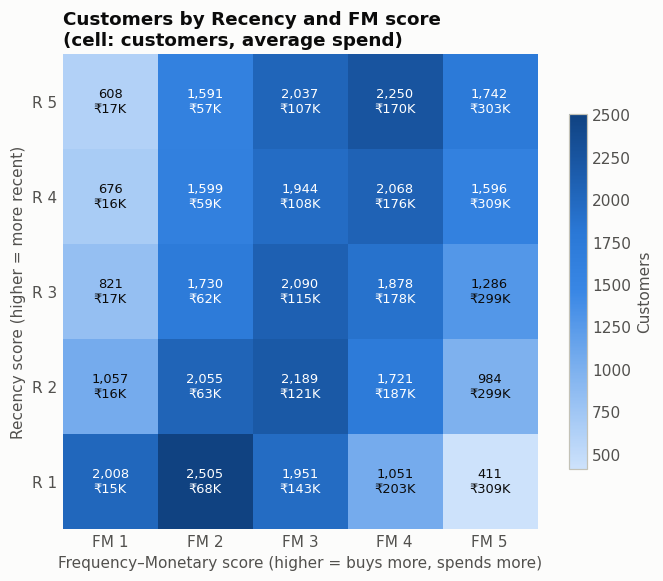

In [5]:
# matplotlib: draw the charts; FuncFormatter formats axis numbers
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap

# plot_style.py (this folder): shared colours and chart defaults for every notebook
import plot_style as ps
ps.apply()

grid_n = full.pivot_table(index="r_score", columns="fm_score", values="monetary", aggfunc="count").sort_index(ascending=False)
grid_m = full.pivot_table(index="r_score", columns="fm_score", values="monetary", aggfunc="mean").sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 5.6))
customers_cmap = LinearSegmentedColormap.from_list("blues", ps.BLUE_RAMP[:7])  # one hue, light -> dark
im = ax.imshow(grid_n.values, cmap=customers_cmap)
for i in range(grid_n.shape[0]):
    for j in range(grid_n.shape[1]):
        n, m = grid_n.values[i, j], grid_m.values[i, j]
        dark = n > np.nanmax(grid_n.values) * 0.55
        label = "–" if np.isnan(n) else f"{n:,.0f}\n{ps.rupees(m)}"
        ax.text(j, i, label, ha="center", va="center", fontsize=8.5,
                color="white" if dark else ps.TEXT_PRIMARY)
ax.set_xticks(range(grid_n.shape[1]), [f"FM {c}" for c in grid_n.columns])
ax.set_yticks(range(grid_n.shape[0]), [f"R {r}" for r in grid_n.index])
ax.set_xlabel("Frequency–Monetary score (higher = buys more, spends more)")
ax.set_ylabel("Recency score (higher = more recent)")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Customers by Recency and FM score\n(cell: customers, average spend)")
fig.colorbar(im, ax=ax, shrink=0.75, label="Customers")
ps.save(fig, "nb02_rfm_grid")
plt.show()

**Reading the grid:** each cell shows how many customers have that combination of scores, and their average spend.

- **Every cell is populated**, from 411 customers (R1, FM5) to 2,505 (R1, FM2).
- **Inactive customers lean towards lower value.** In the R1 row, 4,513 customers sit in FM1–2 but only 411 in FM5. That is expected: customers who order often have usually ordered recently (Recency and Frequency correlate at ρ = −0.32, *[Notebook 1]* Section 4.4).
- **Even so, the high-value but inactive corner is large.** The four cells at R1–2 and FM4–5 (the **At risk** segment) hold 4,167 customers with average spend of ₹187K–₹309K. That corner is where lost buying costs the most.

## 4. Segment profiles

For each segment: its size, its share of valid-order revenue over the full period, and the typical customer's behaviour.

In [6]:
profile = full.groupby("rfm_segment", observed=False).agg(
    customers=("monetary", "count"),
    revenue=("monetary", "sum"),
    recency_days=("recency_days", "median"),
    frequency=("frequency", "median"),
    monetary=("monetary", "median"),
    aov=("aov", "median"),
    coupon_rate=("coupon_rate", "mean"),
    cod_share=("cod_share", "mean"),
    electronics_share=("electronics_share", "mean"),
)
profile.insert(1, "share_of_customers", profile.customers / profile.customers.sum())
profile.insert(3, "share_of_revenue", profile.revenue / profile.revenue.sum())
profile["revenue_per_customer"] = profile.revenue / profile.customers

display(profile.style.format({
    "customers": "{:,.0f}", "share_of_customers": "{:.1%}", "revenue": lambda v: f"₹{v / 1e6:,.1f} M",
    "share_of_revenue": "{:.1%}", "recency_days": "{:,.0f}", "frequency": "{:,.0f}", "monetary": "₹{:,.0f}",
    "aov": "₹{:,.0f}", "coupon_rate": "{:.1%}", "cod_share": "{:.1%}", "electronics_share": "{:.1%}",
    "revenue_per_customer": "₹{:,.0f}"}))
print("Recency, frequency, monetary and AOV are medians; the three shares are means.")

,customers,share_of_customers,revenue,share_of_revenue,recency_days,frequency,monetary,aov,coupon_rate,cod_share,electronics_share,revenue_per_customer
rfm_segment,,,,,,,,,,,,
Champions,"7,656",19.2%,"₹1,767.9 M",33.2%,26,8,"₹209,254","₹27,316",19.9%,31.6%,33.7%,"₹230,922"
Loyal,"9,235",23.2%,"₹1,387.3 M",26.0%,67,6,"₹129,276","₹21,208",20.1%,32.8%,28.8%,"₹150,221"
Recent low spenders,"4,474",11.2%,₹206.3 M,3.9%,28,4,"₹38,767","₹10,002",20.2%,34.4%,15.5%,"₹46,119"
Needs attention,"2,551",6.4%,₹121.1 M,2.3%,85,4,"₹40,172","₹10,555",20.4%,34.0%,17.5%,"₹47,488"
At risk,"4,167",10.5%,₹957.4 M,18.0%,168,7,"₹214,422","₹29,769",20.1%,31.1%,36.2%,"₹229,764"
About to sleep,"4,140",10.4%,₹544.1 M,10.2%,189,5,"₹126,357","₹23,995",20.0%,32.3%,33.2%,"₹131,418"
Hibernating,"7,625",19.1%,₹343.9 M,6.5%,221,3,"₹37,179","₹11,205",20.4%,33.7%,18.5%,"₹45,107"


Recency, frequency, monetary and AOV are medians; the three shares are means.


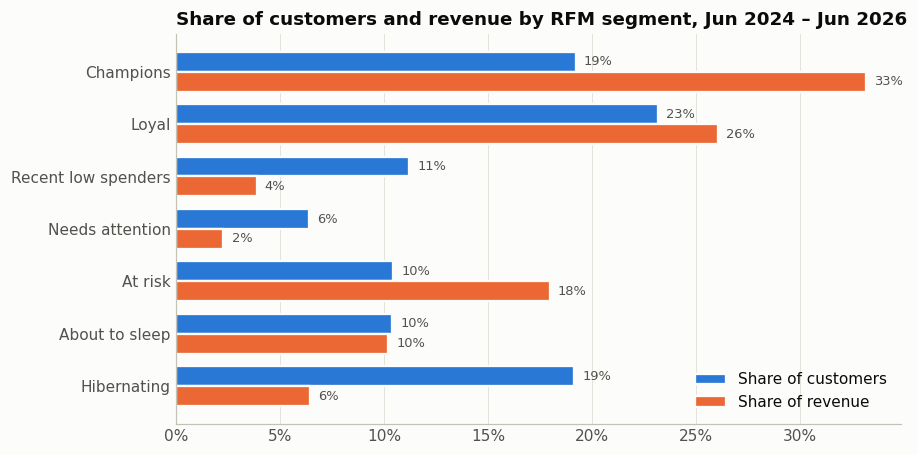

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
y = np.arange(len(SEGMENT_ORDER))
h = 0.38
cust = profile.share_of_customers.reindex(SEGMENT_ORDER).to_numpy()
rev = profile.share_of_revenue.reindex(SEGMENT_ORDER).to_numpy()
ax.barh(y - h / 2, cust, height=h, color=ps.SERIES[0], edgecolor=ps.SURFACE, linewidth=1.5, label="Share of customers")
ax.barh(y + h / 2, rev, height=h, color=ps.SERIES[1], edgecolor=ps.SURFACE, linewidth=1.5, label="Share of revenue")
for yi, c, r in zip(y, cust, rev):
    ax.text(c + 0.004, yi - h / 2, f"{c:.0%}", va="center", fontsize=8.5, color=ps.TEXT_SECONDARY)
    ax.text(r + 0.004, yi + h / 2, f"{r:.0%}", va="center", fontsize=8.5, color=ps.TEXT_SECONDARY)
ax.set_yticks(y, SEGMENT_ORDER)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("Share of customers and revenue by RFM segment, Jun 2024 – Jun 2026")
ax.legend(loc="lower right")
ps.save(fig, "nb02_segment_share")
plt.show()

**Findings** (valid-order revenue, Jun 2024 – Jun 2026):

- **Champions and Loyal customers carry the business.** Together they are **42.4% of customers and 59.2% of revenue**. Champions alone are 19.2% of customers and 33.2% of revenue, with a median of 8 orders and ₹209,254 of spend.
- **At risk is the most urgent segment.** It holds **4,167 customers (10.5%) and ₹957.4 M (18.0%) of revenue**. Its customers spend as much as Champions (median ₹214,422) and order nearly as often (median 7 orders), but their median last order was **168 days** before the snapshot, against 26 days for Champions.
- **The low-value segments are large but contribute little.** Recent low spenders, Needs attention and Hibernating together are 36.7% of customers but 12.7% of revenue. Their median AOV is ₹10,002–₹11,205, about half that of the high-value segments (₹21,208–₹29,769).
- **Electronics share follows value.** High-value segments buy 29%–36% of their orders in Electronics, low-value segments 16%–19%.
- **Coupon use and payment mode barely differ between segments.** Average coupon rate is 19.9%–20.4% and average COD share 31.1%–34.4% in every segment. RFM does not separate customers on these behaviours, which is part of why the K-means model in Notebook 3 includes them directly.

## 5. A first look at the loyalty tiers

Tier is not used to build the segments. Comparing the two is an early check on Objective 2: *does the tier a customer holds match how they actually buy?* The full analysis comes after the K-means segments are built.

customer_tier,Silver,Gold,Platinum
rfm_segment,,,
Champions,0.4%,2.8%,96.7%
Loyal,4.3%,14.2%,81.6%
Recent low spenders,32.9%,34.1%,32.9%
Needs attention,34.3%,30.2%,35.5%
At risk,0.3%,2.4%,97.3%
About to sleep,5.1%,12.9%,82.1%
Hibernating,36.8%,29.4%,33.8%


All scored customers: Silver 14.6%, Gold 16.8%, Platinum 68.6%


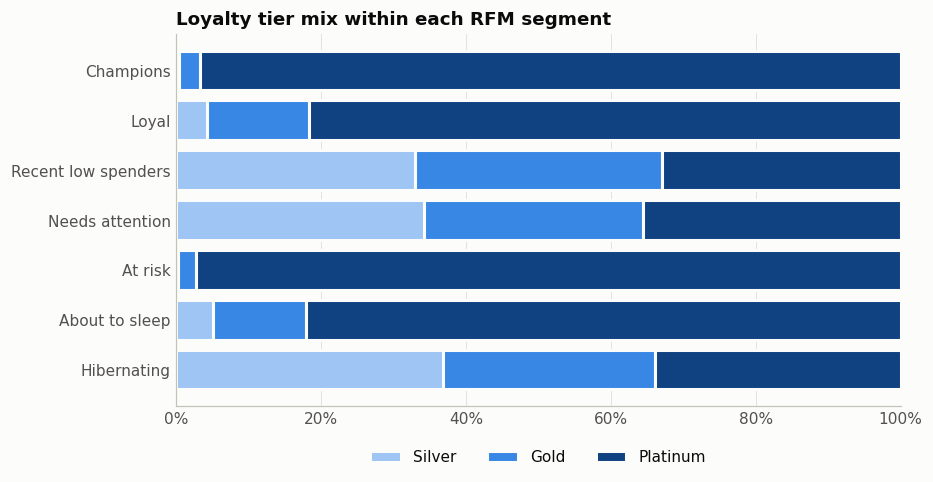

Platinum customers in At risk, About to sleep or Hibernating: 10,030 (36.7% of scored Platinum customers)
Silver or Gold customers in Champions: 251 (3.3% of Champions)


In [8]:
TIER_ORDER = ["Silver", "Gold", "Platinum"]
tier_mix = pd.crosstab(full.rfm_segment, full.customer_tier, normalize="index")[TIER_ORDER]
tier_counts = pd.crosstab(full.rfm_segment, full.customer_tier)[TIER_ORDER]
overall = full.customer_tier.value_counts(normalize=True).reindex(TIER_ORDER)
display(tier_mix.style.format("{:.1%}"))
print("All scored customers:", ", ".join(f"{t} {overall[t]:.1%}" for t in TIER_ORDER))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
left = np.zeros(len(SEGMENT_ORDER))
tier_colors = {"Silver": ps.BLUE_RAMP[1], "Gold": ps.BLUE_RAMP[3], "Platinum": ps.BLUE_RAMP[6]}
for tier in TIER_ORDER:
    vals = tier_mix[tier].reindex(SEGMENT_ORDER).to_numpy()
    ax.barh(SEGMENT_ORDER, vals, left=left, color=tier_colors[tier], edgecolor=ps.SURFACE, linewidth=2, label=tier)
    left += vals
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlim(0, 1)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("Loyalty tier mix within each RFM segment")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
ps.save(fig, "nb02_tier_mix")
plt.show()

platinum_at_risk = tier_counts.loc[["At risk", "About to sleep", "Hibernating"], "Platinum"].sum()
lower_tier_top = tier_counts.loc[["Champions"], ["Silver", "Gold"]].to_numpy().sum()
print(f"Platinum customers in At risk, About to sleep or Hibernating: {platinum_at_risk:,} "
      f"({platinum_at_risk / tier_counts['Platinum'].sum():.1%} of scored Platinum customers)")
print(f"Silver or Gold customers in Champions: {lower_tier_top:,} "
      f"({lower_tier_top / tier_counts.loc['Champions'].sum():.1%} of Champions)")

**Findings:**

- **Tier tracks value, not recency.** Champions are **96.7% Platinum**, but so is At risk (**97.3%**). Platinum status says how much a customer has spent, not whether they are still buying. This supports the charter's hypothesis for Objective 2.
- **10,030 Platinum customers (36.7% of scored Platinum customers) are in a lapsing segment** (At risk, About to sleep or Hibernating). They keep the tier's benefits while their buying has slowed or stopped.
- **Almost no lower-tier customers reach the top.** Only **251 Silver or Gold customers (3.3% of Champions)** are Champions. The low-value segments split roughly a third each across Silver, Gold and Platinum, so a third of the customers in those segments hold Platinum status despite low value.

These are first results from the rule-based segments. Objective 2 is completed after the K-means segments are built.

## 6. The same scoring on the calibration period

Notebook 4 tests whether end-of-2025 segments predict who stopped buying in Jan–Jun 2026. That needs the same scoring applied to the calibration table (orders up to 31 Dec 2025, snapshot 31 Dec 2025).

The cut points are **recalculated** for the calibration period rather than copied from the full period. Recency is measured to a different snapshot date, and Frequency and Monetary cover 19 months instead of 25, so the full-period cut points would not mean the same thing.

In [9]:
calib, calib_cuts = score_rfm(calib)
calib["rfm_segment"] = pd.Categorical([assign_segment(r, fm) for r, fm in zip(calib.r_score, calib.fm_score)],
                                      categories=SEGMENT_ORDER, ordered=True)

display(pd.DataFrame({k: list(v) for k, v in calib_cuts.items()},
                     index=["20th pct", "40th pct", "60th pct", "80th pct"]).T)

compare = pd.DataFrame({
    "full_customers": full.rfm_segment.value_counts().reindex(SEGMENT_ORDER),
    "calib_customers": calib.rfm_segment.value_counts().reindex(SEGMENT_ORDER),
})
compare["full_share"] = compare.full_customers / compare.full_customers.sum()
compare["calib_share"] = compare.calib_customers / compare.calib_customers.sum()
compare.style.format({"full_customers": "{:,.0f}", "calib_customers": "{:,.0f}", "full_share": "{:.1%}", "calib_share": "{:.1%}"})

,20th pct,40th pct,60th pct,80th pct
Recency (days),26.00,61.00,108.00,190.00
Frequency (valid orders),3.00,4.00,5.00,6.00
Monetary (₹),"21,586.16","55,371.81","99,806.81","168,920.63"


,full_customers,calib_customers,full_share,calib_share
rfm_segment,,,,
Champions,"7,656","7,321",19.2%,18.6%
Loyal,"9,235","9,169",23.2%,23.3%
Recent low spenders,"4,474","4,487",11.2%,11.4%
Needs attention,"2,551","2,687",6.4%,6.8%
At risk,"4,167","3,500",10.5%,8.9%
About to sleep,"4,140","3,930",10.4%,10.0%
Hibernating,"7,625","8,337",19.1%,21.1%


**Finding:** the calibration cut points are lower for Frequency and Monetary (for example, the top Monetary cut point is ₹168,921 against ₹215,179), because customers have had 19 months to buy instead of 25. The Recency cut points barely change (26–190 days against 27–195). Segment sizes are similar in the two periods. The main difference is that **At risk is smaller at the end of 2025 (3,500 customers, 8.9%) than at mid-2026 (4,167, 10.5%)**, and Hibernating is larger (21.1% against 19.1%).

Notebook 4 uses these calibration segments to test which of them actually stopped buying in Jan–Jun 2026.

## 7. Save the scores

In [10]:
SCORE_COLS = ["recency_days", "frequency", "monetary", "r_score", "f_score", "m_score", "fm_score", "rfm_cell", "rfm_segment"]
full[SCORE_COLS].to_csv(OUTPUT_DIR / "rfm_scores_full.csv")
calib[SCORE_COLS].to_csv(OUTPUT_DIR / "rfm_scores_calibration.csv")
for f in ["rfm_scores_full.csv", "rfm_scores_calibration.csv"]:
    print(f"Saved 01_data/output/{f}  ({(OUTPUT_DIR / f).stat().st_size / 1e6:.1f} MB)")

Saved 01_data/output/rfm_scores_full.csv  (2.1 MB)
Saved 01_data/output/rfm_scores_calibration.csv  (2.1 MB)


## 8. Summary

| Question | Answer *[NB02]* |
|---|---|
| How are customers scored? | Quintile cut points on the values themselves, so identical customers share a score. Frequency groups are uneven (F1 33.6%, F5 11.7%) because order counts are whole numbers |
| Which segments carry the business? | Champions and Loyal: 42.4% of customers, 59.2% of revenue |
| Where is the biggest revenue risk? | At risk: 4,167 customers holding ₹957.4 M (18.0%) of revenue, spending like Champions but with a median of 168 days since their last order |
| Do coupons or payment mode separate the segments? | No. Coupon rate (about 20%) and COD share (31%–34%) are almost the same in every segment |
| Does tier match behaviour? | Tier follows spend, not recency: At risk is 97.3% Platinum. 10,030 Platinum customers (36.7%) are in lapsing segments, and only 251 Silver or Gold customers are Champions |

### What this sets up

- **Notebook 3 (K-means)** will be compared with these seven segments. RFM leaves coupon use, payment mode and category mix out entirely, so the comparison will show whether adding those behaviours finds groups that RFM misses.
- **Notebook 4 (validation)** will test the calibration segments against what customers actually did in Jan–Jun 2026, starting with whether the 3,500 At risk customers of end-2025 really stopped buying.
- **Objective 2** has a first answer: the tier system rewards past spend but does not notice when valuable customers go quiet.